# Analisis churn pelanggan Telco (IBM sample data)

Pertanyaan utama: **segmen pelanggan mana (kontrak, tenure, layanan, metode bayar) yang paling banyak churn, dan berapa revenue bulanan yang hilang?**

Analisis deskriptif tanpa model prediksi. Semua angka dibaca dari `results/2-analysis/*.csv` (hasil SQL DuckDB yang sudah dicek silang dengan pandas). Pola adalah asosiasi, bukan sebab-akibat. Angka dampak berlabel *estimated*.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
R = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'results' / '2-analysis').exists()) / 'results' / '2-analysis'
rd = lambda f: pd.read_csv(R / f)
MIN_N = 30
def barh(df, label, val='churn_rate', n='n', title='', xmax=None):
    d = df.copy(); d = d[d[n] >= MIN_N]
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(d) + 1))
    ax.barh(d[label].astype(str), d[val], color='#1A73E8'); ax.invert_yaxis()
    for i, (v, k) in enumerate(zip(d[val], d[n])): ax.text(v + 0.5, i, f'{v:.1f}% (n={k:,})', va='center', fontsize=8)
    ax.set_xlabel('Churn rate (%)'); ax.set_title(title); ax.set_xlim(0, xmax or d[val].max() * 1.35); plt.tight_layout(); plt.show()

## KPI

In [2]:
rd('kpi_overall.csv')

,kpi_id,kpi,value,n
0,K1,Churn rate (%),26.54,7043
1,K2,Retention rate (%),73.46,7043
2,K3,Lost MRR: tagihan bulanan pelanggan churn (US$),"139,130.85",1869
3,K4,ARPU: rata-rata MonthlyCharges semua pelanggan...,64.76,7043
4,K5,"Revenue terselamatkan per tahun, skenario chur...","265,327.39",2602


## Q1-Q2 Churn per kontrak dan per tenure

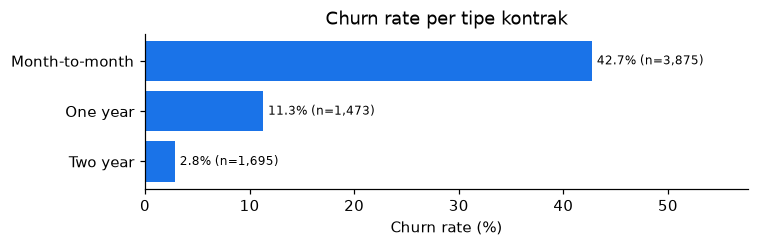

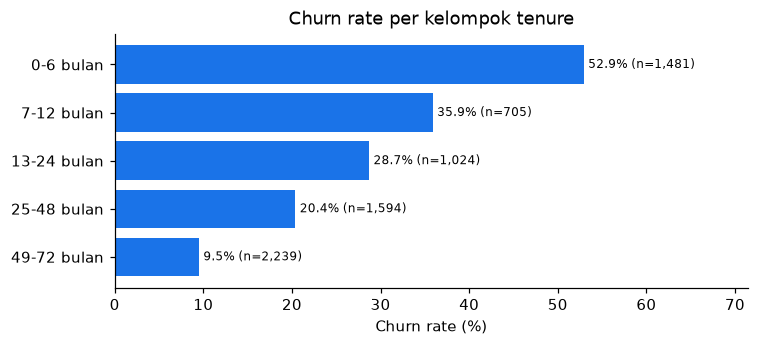

,contract,n,churned,churn_rate,share_of_churners,share_of_customers
0,Month-to-month,3875,1655,42.71,88.55,55.02
1,One year,1473,166,11.27,8.88,20.91
2,Two year,1695,48,2.83,2.57,24.07


In [3]:
barh(rd('churn_by_contract.csv'), 'contract', title='Churn rate per tipe kontrak')
barh(rd('churn_by_tenure.csv'), 'tenure_bucket', title='Churn rate per kelompok tenure')
rd('churn_by_contract.csv')

## Q3 Kurva retensi (Kaplan-Meier, pendekatan dari tenure)
Bukan kurva kohort sebenarnya; ujung kurva berbasis sedikit pelanggan.

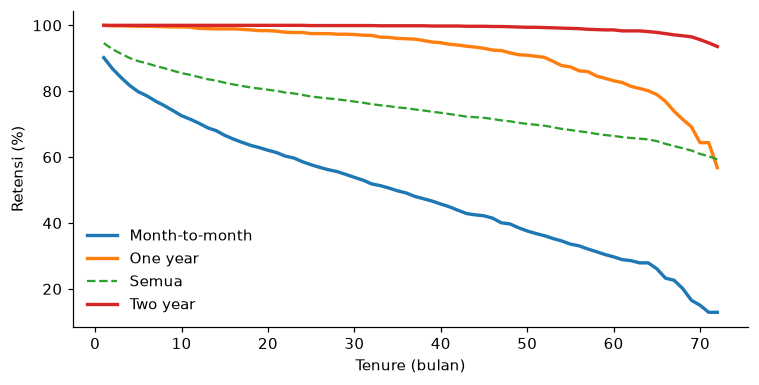

In [4]:
km = rd('retention_curve.csv')
fig, ax = plt.subplots(figsize=(7, 3.6))
for g, d in km.groupby('contract'): ax.plot(d.month, d.retention_pct, label=g, lw=2.2 if g != 'Semua' else 1.5, ls='--' if g == 'Semua' else '-')
ax.set_xlabel('Tenure (bulan)'); ax.set_ylabel('Retensi (%)'); ax.legend(frameon=False); plt.tight_layout(); plt.show()

## Q4-Q5 Layanan dan bundling (pelanggan internet saja untuk layanan tambahan)

In [5]:
s = rd('churn_by_service_internet.csv'); s = s[s.status.isin(['Yes', 'No'])]
p = s.pivot_table(index=['internet_service', 'service_name'], columns='status', values='churn_rate').reset_index()
p['selisih_pts'] = p['Yes'] - p['No']; p.sort_values(['internet_service', 'selisih_pts'])

status,internet_service,service_name,No,Yes,selisih_pts
2,DSL,OnlineSecurity,27.96,9.49,-18.47
5,DSL,TechSupport,27.76,9.68,-18.08
1,DSL,OnlineBackup,25.69,10.68,-15.01
0,DSL,DeviceProtection,25.22,10.99,-14.23
4,DSL,StreamingTV,22.68,13.27,-9.41
3,DSL,StreamingMovies,22.36,13.97,-8.39
8,Fiber optic,OnlineSecurity,49.36,21.81,-27.55
11,Fiber optic,TechSupport,49.37,22.63,-26.74
7,Fiber optic,OnlineBackup,50.77,30.31,-20.46
6,Fiber optic,DeviceProtection,49.97,31.54,-18.43


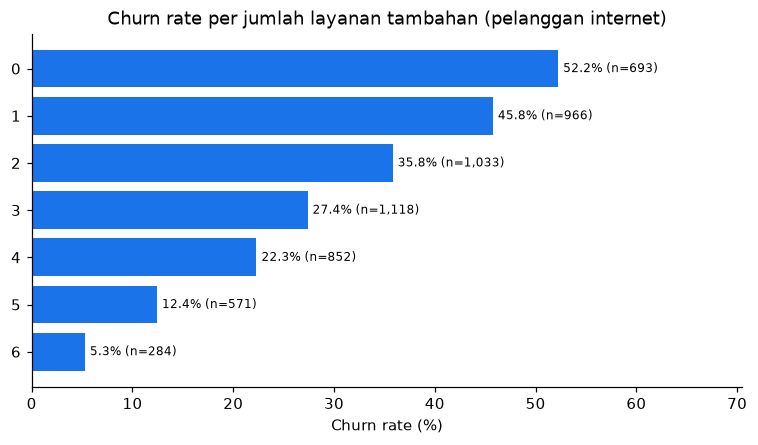

In [6]:
barh(rd('churn_by_addons.csv'), 'n_addons', title='Churn rate per jumlah layanan tambahan (pelanggan internet)')

## Q6-Q7 Metode bayar, paperless, dan kombinasi segmen

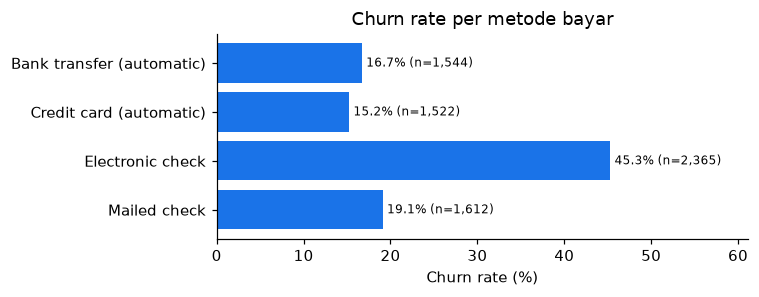

contract,Month-to-month,One year,Two year
payment_method,,,
Bank transfer (automatic),34.13,9.72,3.37
Credit card (automatic),32.78,10.30,2.24
Electronic check,53.73,18.44,7.74
Mailed check,31.58,6.82,0.79


In [7]:
barh(rd('churn_by_payment.csv'), 'payment_method', title='Churn rate per metode bayar')
rd('churn_payment_x_contract.csv').pivot(index='payment_method', columns='contract', values='churn_rate')

In [8]:
seg = rd('segments.csv'); seg['ok_reco'] = seg.n >= 100
seg.head(10)

,contract,internet_service,payment_method,n,churned,churn_rate,arpu,lost_mrr,ok_reco
0,Month-to-month,Fiber optic,Electronic check,1307,789,60.37,87.18,"68,281.50",True
1,Month-to-month,Fiber optic,Bank transfer (automatic),327,149,45.57,88.25,"13,062.10",True
2,Month-to-month,Fiber optic,Credit card (automatic),293,122,41.64,87.97,"10,731.15",True
3,Month-to-month,DSL,Electronic check,474,192,40.51,49.25,"8,776.45",True
4,Month-to-month,Fiber optic,Mailed check,201,102,50.75,82.59,"8,407.25",True
5,Month-to-month,DSL,Mailed check,367,113,30.79,48.84,"5,292.10",True
6,One year,Fiber optic,Electronic check,196,51,26.02,99.16,"5,149.65",True
7,Month-to-month,DSL,Credit card (automatic),185,50,27.03,52.17,"2,474.80",True
8,One year,Fiber optic,Credit card (automatic),150,23,15.33,99.16,"2,392.35",True
9,One year,Fiber optic,Bank transfer (automatic),157,23,14.65,98.17,"2,344.35",True


## Q8 Demografi

In [9]:
rd('churn_by_demographics.csv')

,factor,level,n,churned,churn_rate
0,dependents,No,4933,1543,31.28
1,dependents,Yes,2110,326,15.45
2,gender,Female,3488,939,26.92
3,gender,Male,3555,930,26.16
4,partner,No,3641,1200,32.96
5,partner,Yes,3402,669,19.66
6,senior_citizen,Non-senior,5901,1393,23.61
7,senior_citizen,Senior,1142,476,41.68


Setelah kontrak dikendalikan, perbedaan senior vs non-senior tetap ada tetapi mengecil:

In [10]:
rd('churn_senior_x_contract.csv')

,contract,senior_group,n,churned,churn_rate
0,Month-to-month,Non-senior,3068,1214,39.57
1,Month-to-month,Senior,807,441,54.65
2,One year,Non-senior,1283,137,10.68
3,One year,Senior,190,29,15.26
4,Two year,Non-senior,1550,42,2.71
5,Two year,Senior,145,6,4.14


## Q9 Lost MRR (Pareto)

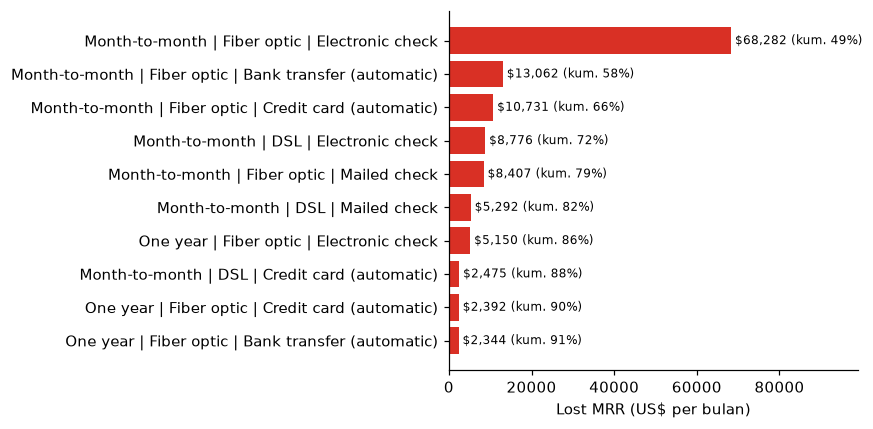

In [11]:
pa = rd('pareto_lost_mrr.csv').head(10); pa['segmen'] = pa.contract + ' | ' + pa.internet_service + ' | ' + pa.payment_method
fig, ax = plt.subplots(figsize=(8, 4)); ax.barh(pa.segmen, pa.lost_mrr, color='#D93025'); ax.invert_yaxis()
for i, (v, c) in enumerate(zip(pa.lost_mrr, pa.cum_share_lost_mrr)): ax.text(v, i, f' ${v:,.0f} (kum. {c:.0f}%)', va='center', fontsize=8)
ax.set_xlabel('Lost MRR (US$ per bulan)'); ax.set_xlim(0, pa.lost_mrr.max() * 1.45); plt.tight_layout(); plt.show()

## Q10 Tagihan bulanan: churn vs bertahan

In [12]:
rd('monthly_charges_churn.csv')

,churn,n,mean_charge,median_charge,p25_charge,p75_charge
0,No,5174,61.27,64.43,25.10,88.40
1,Yes,1869,74.44,79.65,56.15,94.20


## Q11-Q12 Skenario program retensi (estimated)
Revenue terselamatkan per tahun = (churn lama - churn baru) x pelanggan segmen x ARPU x 12. Batas biaya impas = revenue terselamatkan / pelanggan segmen.

In [13]:
sc = rd('breakeven.csv'); sc['segmen'] = sc.contract + ' | ' + sc.internet_service + ' | ' + sc.payment_method
sc.pivot(index='segmen', columns='cut_pct', values='saved_revenue_year')

cut_pct,10,20,30
segmen,,,
Month-to-month | DSL | Electronic check,"11,348.23","22,696.46","34,044.69"
Month-to-month | Fiber optic | Bank transfer (automatic),"15,780.57","31,561.14","47,341.72"
Month-to-month | Fiber optic | Credit card (automatic),"12,879.36","25,758.71","38,638.07"
Month-to-month | Fiber optic | Electronic check,"82,545.78","165,091.56","247,637.34"
Month-to-month | Fiber optic | Mailed check,"10,109.76","20,219.52","30,329.28"


In [14]:
sc.pivot(index='segmen', columns='cut_pct', values='breakeven_cost_per_customer_year')

cut_pct,10,20,30
segmen,,,
Month-to-month | DSL | Electronic check,23.94,47.88,71.82
Month-to-month | Fiber optic | Bank transfer (automatic),48.26,96.52,144.78
Month-to-month | Fiber optic | Credit card (automatic),43.96,87.91,131.87
Month-to-month | Fiber optic | Electronic check,63.16,126.31,189.47
Month-to-month | Fiber optic | Mailed check,50.30,100.59,150.89


## Validasi
Signifikansi dan kekuatan hubungan (Cramer's V), selisih mentah vs setelah kontrak dan tenure disamakan, sensitivitas, dan status hipotesis.

In [15]:
rd('significance.csv')

,factor,n,levels,chi2,dof,p_value,cramers_v,rate_min,rate_max,gap_pts
0,Tipe kontrak,7043,3,"1,184.60",2,0.00,0.41,2.83,42.71,39.88
1,Kelompok tenure,7043,5,927.30,4,0.00,0.36,9.51,52.94,43.42
2,Jenis internet,7043,3,732.30,2,0.00,0.32,7.40,41.89,34.49
3,Metode bayar,7043,4,648.10,3,0.00,0.30,15.24,45.29,30.04
4,Online Security (pelanggan internet),5517,2,435.10,1,0.00,0.28,14.61,41.77,27.16
5,Jumlah layanan tambahan (pelanggan internet),5517,4,431.10,3,0.00,0.28,10.06,52.24,42.18
6,Tech Support (pelanggan internet),5517,2,415.50,1,0.00,0.27,15.17,41.64,26.47
7,Paperless billing,7043,2,259.20,1,0.00,0.19,16.33,33.57,17.24
8,Dependents,7043,2,189.90,1,0.00,0.16,15.45,31.28,15.83
9,Senior citizen,7043,2,160.40,1,0.00,0.15,23.61,41.68,18.08


In [16]:
rd('adjusted_gaps.csv')

,perbandingan,selisih_mentah_pts,selisih_setelah_strata_pts,strata_dipakai,bagian_selisih_yang_tersisa_pct
0,Electronic check vs metode lain,28.23,14.84,11,52.60
1,Fiber optic vs DSL (pelanggan internet),22.93,19.64,10,85.70
2,Paperless billing vs tidak,17.24,12.91,12,74.90
3,Punya Online Security vs tidak (pelanggan inte...,-27.16,-12.85,11,47.30
4,Punya Tech Support vs tidak (pelanggan internet),-26.47,-10.56,11,39.90
5,Senior vs non-senior,18.08,12.58,9,69.60
6,Punya partner vs tidak,-13.29,0.38,15,-2.80


In [17]:
rd('sensitivity.csv')

,metric,dasar,tanpa_tenure_0,tanpa_totalcharges_janggal,diff_pct_tanpa_tenure_0,flag_review
0,churn_rate,26.537,26.578,26.586,0.16,False
1,churn_M2M,42.71,42.71,42.721,0.00,False
2,churn_TwoYear,2.832,2.849,2.85,0.59,False
3,churn_Fiber,41.893,41.893,41.893,0.00,False
4,churn_ElectronicCheck,45.285,45.285,45.285,0.00,False
5,churn_tenure_0_6,52.937,53.333,53.406,0.75,False
6,lost_mrr,139130.85,139130.85,139130.85,0.00,False
7,top1_share_lost_mrr,49.077,49.077,49.077,0.00,False
8,top1_segment,Month-to-month | Fiber optic | Electronic check,Month-to-month | Fiber optic | Electronic check,Month-to-month | Fiber optic | Electronic check,NaN,False


In [18]:
pd.set_option('display.max_colwidth', None); rd('hypotheses.csv')

,id,hipotesis,bukti,kesimpulan
0,H1,Kontrak Month-to-month jauh lebih sering churn daripada kontrak tahunan,M2M 42.7% vs One year 11.3% vs Two year 2.8%,Didukung
1,H2,Churn paling tinggi di 12 bulan pertama,"0-6 bulan 52.9%, 7-12 bulan 35.9%, 13-24 bulan 28.7%",Didukung
2,H3,Fiber optic dan Electronic check lebih sering churn,"Fiber vs DSL: mentah +22.93 poin, setelah strata +19.64; Electronic check vs lain: mentah +28.23, setelah strata +14.84","Didukung (selisih mengecil setelah kontrol kontrak dan tenure, tetapi tetap ada)"
3,H4,Pelanggan dengan Online Security dan Tech Support lebih jarang churn,"Online Security: mentah -27.16 poin, setelah strata -12.85; Tech Support: mentah -26.47, setelah strata -10.56","Didukung (selisih mengecil setelah kontrol, tetapi tetap negatif)"
4,H5,Sebagian besar revenue hilang berasal dari sedikit segmen,5 dari 34 segmen menyumbang 78.5% lost MRR dengan 36.9% pelanggan; segmen teratas saja 49.1%,Didukung


In [19]:
pd.set_option('display.max_colwidth', 80); rd('crosscheck.csv')[['check', 'status', 'max_abs_diff']]

,check,status,max_abs_diff
0,Q1 churn per kontrak,PASS,0.00
1,Q2 churn per tenure bucket,PASS,0.00
2,Q2 tenure x kontrak,PASS,0.00
3,Q4 churn per jenis internet,PASS,0.00
4,Q4 churn per layanan,PASS,0.00
5,Q5 churn per jumlah layanan tambahan,PASS,0.00
6,Q6 churn per metode bayar,PASS,0.00
7,Q6 churn per paperless,PASS,0.00
8,Q6 kontrak x metode bayar,PASS,0.00
9,Q7 segmen kontrak x internet x bayar,PASS,0.00
